In [14]:
import pandas as pd
import numpy as np
import kagglehub
import os

In [15]:
path = kagglehub.dataset_download("isaacfemiogunniyi/co2-emission-of-vehicles-in-canada")

df = pd.read_csv(os.path.join(path, "CO2 Emissions_Canada.csv"))
df.head()

Using Colab cache for faster access to the 'co2-emission-of-vehicles-in-canada' dataset.


,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


# EDA

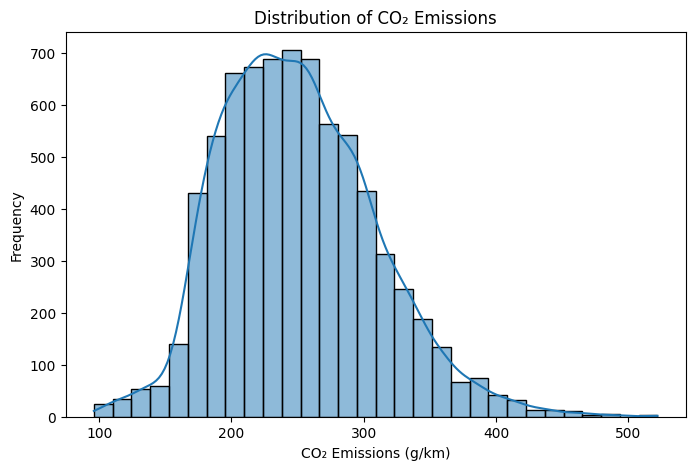

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.histplot(df["CO2 Emissions(g/km)"],
             bins=30,
             kde=True)

plt.title("Distribution of CO₂ Emissions")
plt.xlabel("CO₂ Emissions (g/km)")
plt.ylabel("Frequency")
plt.show()

In [17]:
print(df.isnull().sum())

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64


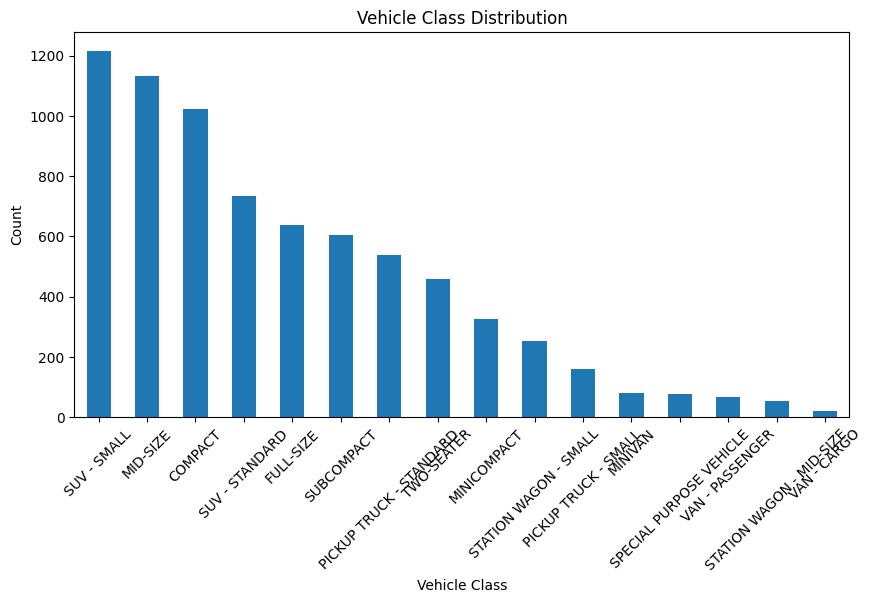

In [18]:
vehicle_counts = df["Vehicle Class"].value_counts()

vehicle_counts.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Vehicle Class Distribution")
plt.xlabel("Vehicle Class")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

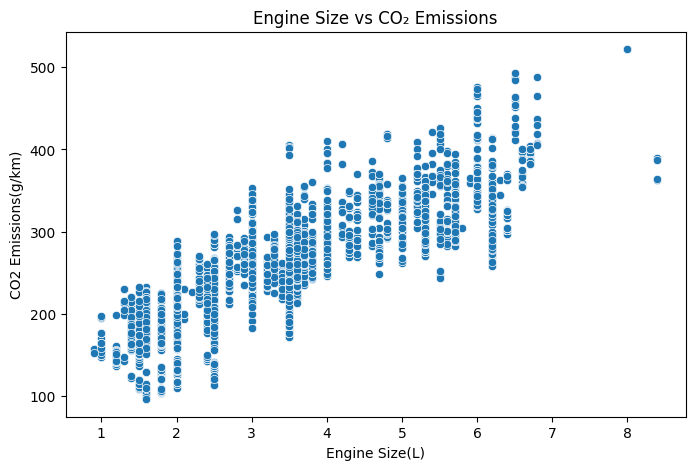

In [19]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Engine Size(L)",
    y="CO2 Emissions(g/km)"
)

plt.title("Engine Size vs CO₂ Emissions")
plt.show()

# Preprocessing

Process Vehicle Class to its average weight



In [20]:
size_to_avg_weight = {
    'TWO-SEATER': 1100,
    'MINICOMPACT': 1150,
    'SUBCOMPACT': 1250,
    'COMPACT': 1350,
    'STATION WAGON - SMALL': 1400,
    'MID-SIZE': 1600,
    'STATION WAGON - MID-SIZE': 1650,
    'SUV - SMALL': 1800,
    'FULL-SIZE': 1900,
    'SUV - STANDARD': 2200,
    'MINIVAN': 2200,
    'PICKUP TRUCK - SMALL': 2300,
    'PICKUP TRUCK - STANDARD': 2600,
    'VAN - PASSENGER': 2500,
    'VAN - CARGO': 2700,
    'SPECIAL PURPOSE VEHICLE': 2800
}

df['vehicle_class_num'] = df['Vehicle Class'].map(size_to_avg_weight)
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km),vehicle_class_num
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196,1350
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221,1350
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136,1350
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255,1800
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244,1800


Process Transmission with one hot encoding

In [21]:
df['trans_type'] = df['Transmission'].str.extract(r'([A-Z]+)')

df = pd.get_dummies(
    df,
    columns=['trans_type'],
    prefix='trans',
    dtype=int
)
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km),vehicle_class_num,trans_A,trans_AM,trans_AS,trans_AV,trans_M
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196,1350,0,0,1,0,0
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221,1350,0,0,0,0,1
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136,1350,0,0,0,1,0
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255,1800,0,0,1,0,0
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244,1800,0,0,1,0,0


Process Fuel Type with one hot encoding

In [22]:
df = pd.get_dummies(df, columns=['Fuel Type'], prefix='fuel', dtype=int)

df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),...,trans_A,trans_AM,trans_AS,trans_AV,trans_M,fuel_D,fuel_E,fuel_N,fuel_X,fuel_Z
0,ACURA,ILX,COMPACT,2.0,4,AS5,9.9,6.7,8.5,33,...,0,0,1,0,0,0,0,0,0,1
1,ACURA,ILX,COMPACT,2.4,4,M6,11.2,7.7,9.6,29,...,0,0,0,0,1,0,0,0,0,1
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,6.0,5.8,5.9,48,...,0,0,0,1,0,0,0,0,0,1
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,12.7,9.1,11.1,25,...,0,0,1,0,0,0,0,0,0,1
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,12.1,8.7,10.6,27,...,0,0,1,0,0,0,0,0,0,1


Not including Fuel Consumption columns as features to make it not too easy to predict

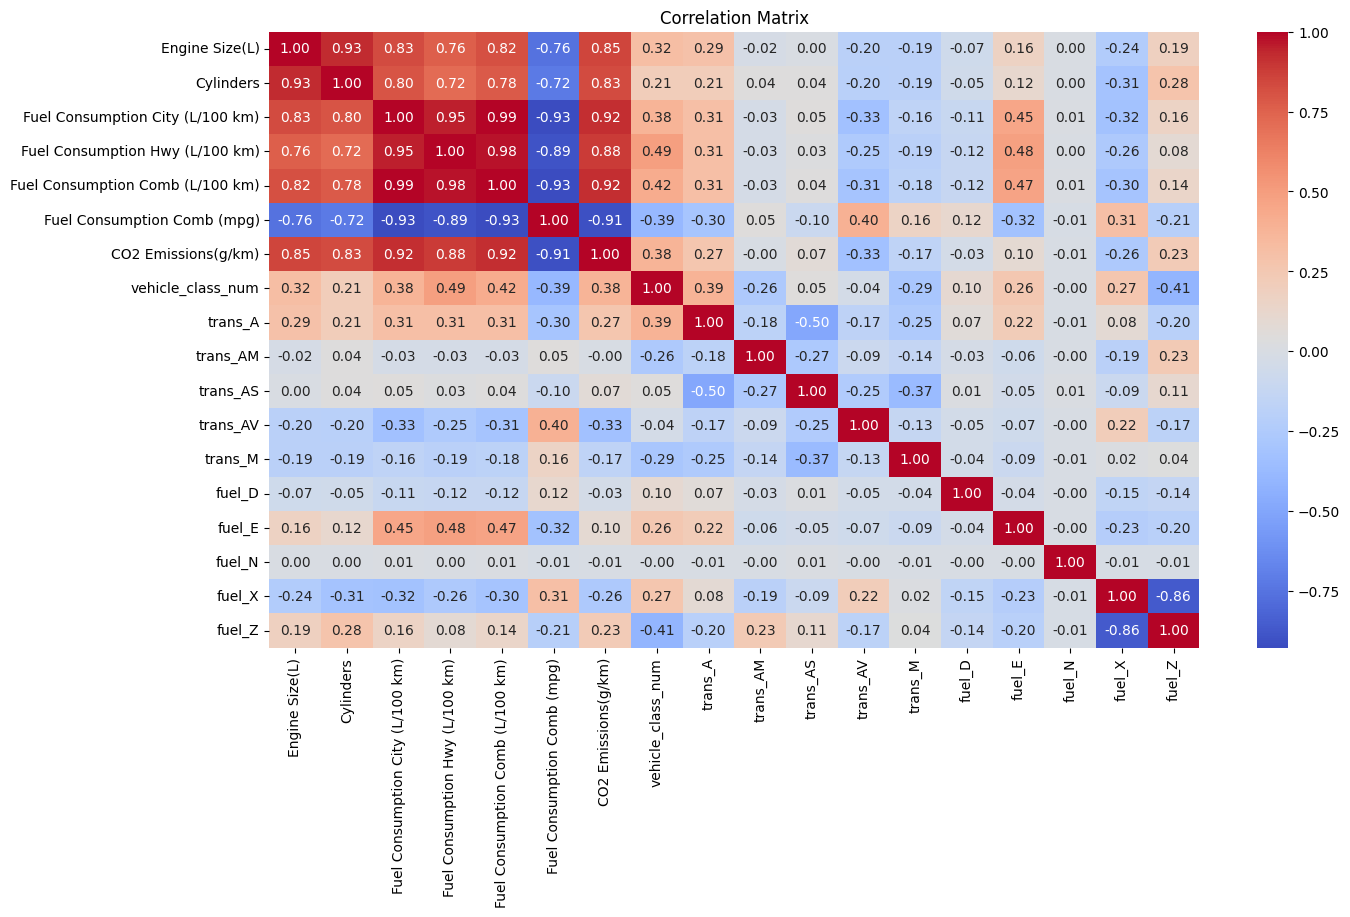

In [23]:
plt.figure(figsize=(15,8))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [24]:
new_df = df[['Engine Size(L)',
             'Cylinders',
             'vehicle_class_num',
             'trans_A',
             'trans_AM',
             'trans_AS',
             'trans_AV',
             'trans_M',
             'fuel_D',
             'fuel_E',
             'fuel_N',
             'fuel_X',
             'fuel_Z',
             'CO2 Emissions(g/km)'
             ]]


new_df.head()

,Engine Size(L),Cylinders,vehicle_class_num,trans_A,trans_AM,trans_AS,trans_AV,trans_M,fuel_D,fuel_E,fuel_N,fuel_X,fuel_Z,CO2 Emissions(g/km)
0,2.0,4,1350,0,0,1,0,0,0,0,0,0,1,196
1,2.4,4,1350,0,0,0,0,1,0,0,0,0,1,221
2,1.5,4,1350,0,0,0,1,0,0,0,0,0,1,136
3,3.5,6,1800,0,0,1,0,0,0,0,0,0,1,255
4,3.5,6,1800,0,0,1,0,0,0,0,0,0,1,244


In [25]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import matplotlib.pyplot as plt

In [26]:
# Drop rows with missing values
new_df = new_df.dropna()

In [27]:
X = new_df.drop(columns=['CO2 Emissions(g/km)'])
Y = new_df['CO2 Emissions(g/km)']
arr = []

In [28]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)


print("Train size:", X_train.shape[0])
print("Validation size:", X_val.shape[0])
print("Test size:", X_test.shape[0])

Train size: 5169
Validation size: 1108
Test size: 1108


XGBoost

Hyperparameter finetuning to get the best learning rate and max depth

Best parameters: learning_rate=0.2, max_depth=6


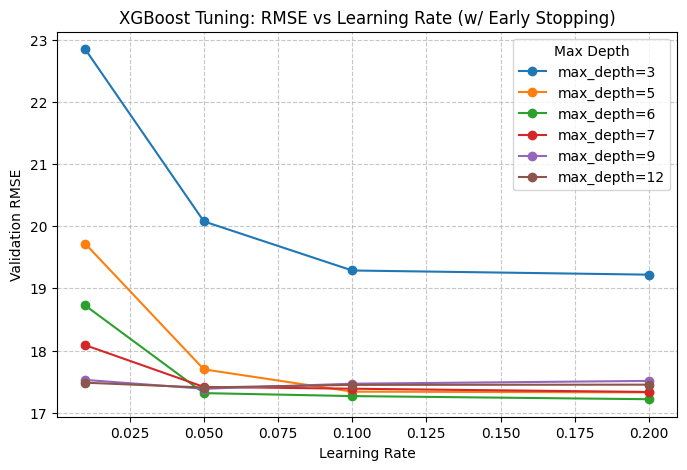

In [29]:
import itertools

learning_rates = [0.01, 0.05, 0.1, 0.2]
max_depths = [3, 5, 6, 7, 9, 12]

best_rmse = float('inf')
best_params = {'learning_rate': 0.1, 'max_depth': 6}

plot_results = {depth: [] for depth in max_depths}

for depth in max_depths:
    for lr in learning_rates:
        xgb_tune = xgb.XGBRegressor(
            n_estimators=500,
            learning_rate=lr,
            max_depth=depth,
            random_state=42,
            eval_metric="rmse",
            early_stopping_rounds=20,
            n_jobs=-1
        )

        xgb_tune.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        y_val_pred = xgb_tune.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
        plot_results[depth].append(rmse)

        if rmse < best_rmse:
            best_rmse = rmse
            best_params['learning_rate'] = lr
            best_params['max_depth'] = depth

print(f"Best parameters: learning_rate={best_params['learning_rate']}, max_depth={best_params['max_depth']}")

plt.figure(figsize=(8, 5))
for depth in max_depths:
    plt.plot(learning_rates, plot_results[depth], marker='o', label=f'max_depth={depth}')

plt.xlabel("Learning Rate")
plt.ylabel("Validation RMSE")
plt.title("XGBoost Tuning: RMSE vs Learning Rate (w/ Early Stopping)")
plt.legend(title="Max Depth")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [30]:
model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=best_params['learning_rate'],
    max_depth=best_params['max_depth'],
    eval_metric=["rmse", "mae"],
    random_state=42,
    early_stopping_rounds=20
)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)
y_pred = model.predict(X_test)

import pickle

# save model
pickle.dump(model, open("model.pkl", "wb"))

# save feature columns
pickle.dump(X.columns.tolist(), open("feature_columns.pkl", "wb"))

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))

arr.append([mean_absolute_error(y_test, y_pred), np.sqrt(mean_squared_error(y_test, y_pred)), r2_score(y_test, y_pred)])

MAE : 11.216861724853516
RMSE: 15.404572618023042
R²  : 0.9295957088470459


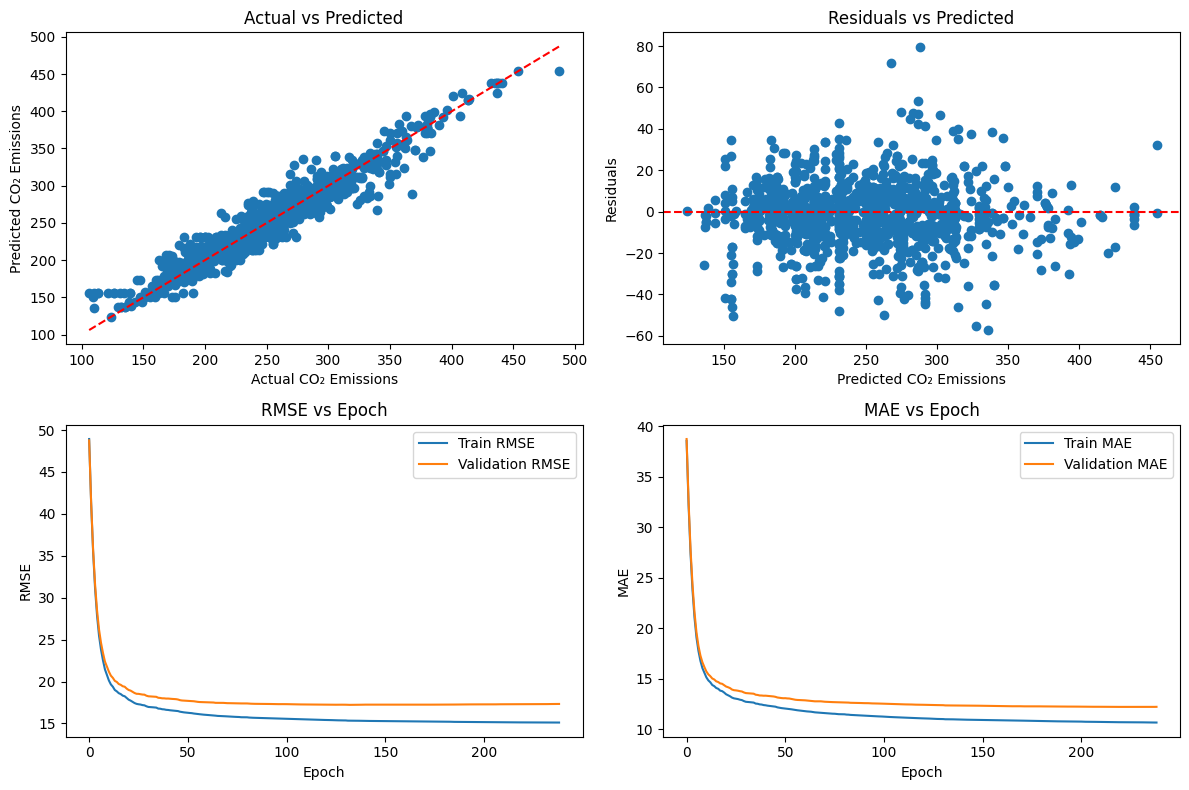

In [31]:
results = model.evals_result()
train_mae = results['validation_0']['mae']
val_mae   = results['validation_1']['mae']
train_rmse = results['validation_0']['rmse']
val_rmse   = results['validation_1']['rmse']
residuals = y_test - y_pred

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

#Actual vs Predicted
axes[0, 0].scatter(y_test, y_pred)
axes[0, 0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="red"
)
axes[0, 0].set_title("Actual vs Predicted")
axes[0, 0].set_xlabel("Actual CO₂ Emissions")
axes[0, 0].set_ylabel("Predicted CO₂ Emissions")

#Residuals vs Predicted
axes[0, 1].scatter(y_pred, residuals)
axes[0, 1].axhline(0, linestyle="--", color="red")
axes[0, 1].set_title("Residuals vs Predicted")
axes[0, 1].set_xlabel("Predicted CO₂ Emissions")
axes[0, 1].set_ylabel("Residuals")

#RMSE vs Epoch
axes[1, 0].plot(train_rmse, label="Train RMSE")
axes[1, 0].plot(val_rmse, label="Validation RMSE")
axes[1, 0].set_title("RMSE vs Epoch")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("RMSE")
axes[1, 0].legend()

#MAE vs Epoch
axes[1, 1].plot(train_mae, label="Train MAE")
axes[1, 1].plot(val_mae, label="Validation MAE")
axes[1, 1].set_title("MAE vs Epoch")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("MAE")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

Decision Tree

Hyperparameter finetuning to get the best depth

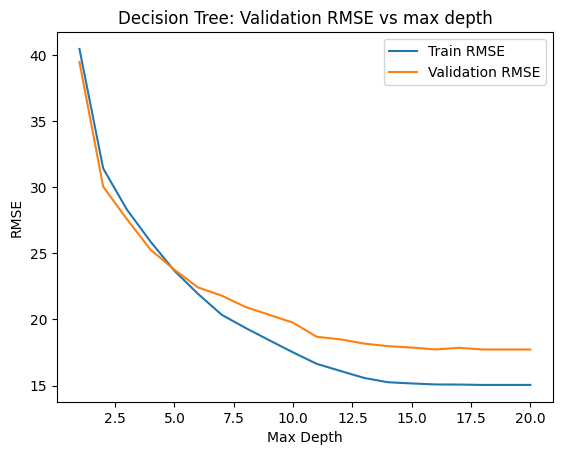

19


In [32]:
depths = range(1, 21)
train_rmse = []
val_rmse = []

for d in depths:
    dt = DecisionTreeRegressor(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)

    y_train_pred = dt.predict(X_train)
    y_val_pred = dt.predict(X_val)

    train_rmse.append(
        np.sqrt(mean_squared_error(y_train, y_train_pred))
    )
    val_rmse.append(
        np.sqrt(mean_squared_error(y_val, y_val_pred))
    )

best_depth = depths[np.argmin(val_rmse)]

plt.figure()
plt.plot(depths, train_rmse, label="Train RMSE")
plt.plot(depths, val_rmse, label="Validation RMSE")
plt.xlabel("Max Depth")
plt.ylabel("RMSE")
plt.title("Decision Tree: Validation RMSE vs max depth")
plt.legend()
plt.show()

print(best_depth)

In [33]:
model = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))

arr.append([mean_absolute_error(y_test, y_pred), np.sqrt(mean_squared_error(y_test, y_pred)), r2_score(y_test, y_pred)]);

MAE : 11.106329155205183
RMSE: 15.450722460124055
R²  : 0.9291732456488757


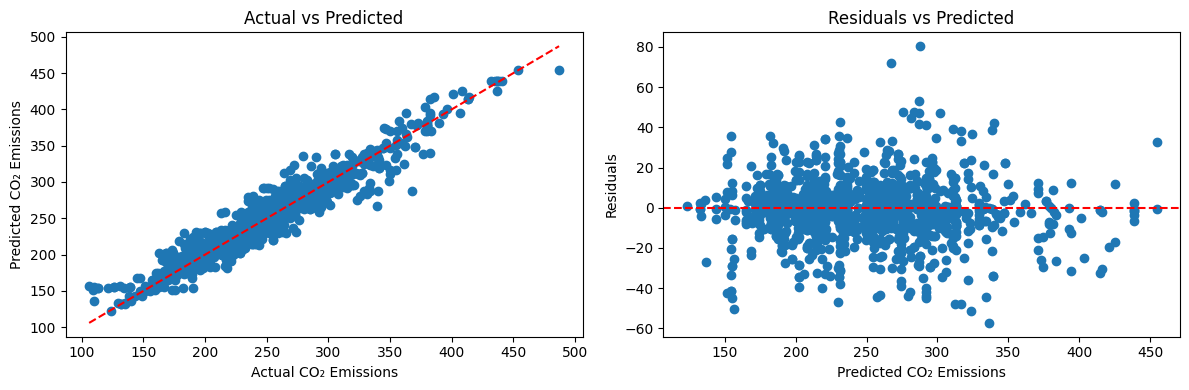

In [34]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Actual vs Predicted
axes[0].scatter(y_test, y_pred)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="red"
)
axes[0].set_xlabel("Actual CO₂ Emissions")
axes[0].set_ylabel("Predicted CO₂ Emissions")
axes[0].set_title("Actual vs Predicted")

#Residuals vs Predicted
axes[1].scatter(y_pred, residuals)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_xlabel("Predicted CO₂ Emissions")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs Predicted")

plt.tight_layout()
plt.show()

Random Forest

Hyperparameter finetuning to get the best number of tree

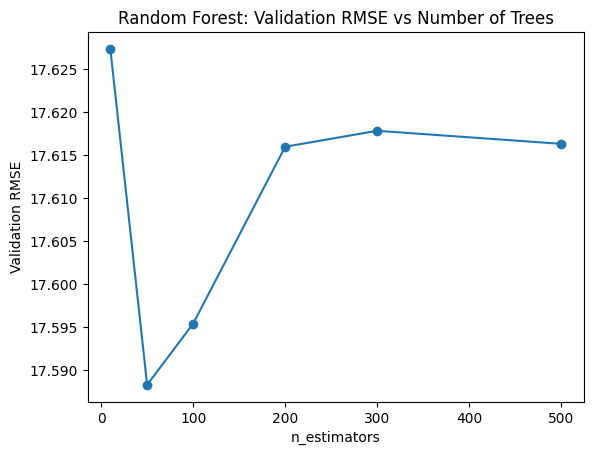

Best n_estimators: 50


In [35]:
trees = [10, 50, 100, 200, 300, 500]
val_rmse = []

for n in trees:
    rf = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)

    y_val_pred = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    val_rmse.append(rmse)

plt.figure()
plt.plot(trees, val_rmse, marker="o")
plt.xlabel("n_estimators")
plt.ylabel("Validation RMSE")
plt.title("Random Forest: Validation RMSE vs Number of Trees")
plt.show()

best_n = trees[np.argmin(val_rmse)]
print("Best n_estimators:", best_n)

In [36]:
model = RandomForestRegressor(
    n_estimators=best_n,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))

arr.append([mean_absolute_error(y_test, y_pred), np.sqrt(mean_squared_error(y_test, y_pred)), r2_score(y_test, y_pred)]);

MAE : 11.20240445509502
RMSE: 15.399252518165591
R²  : 0.9296443403859371


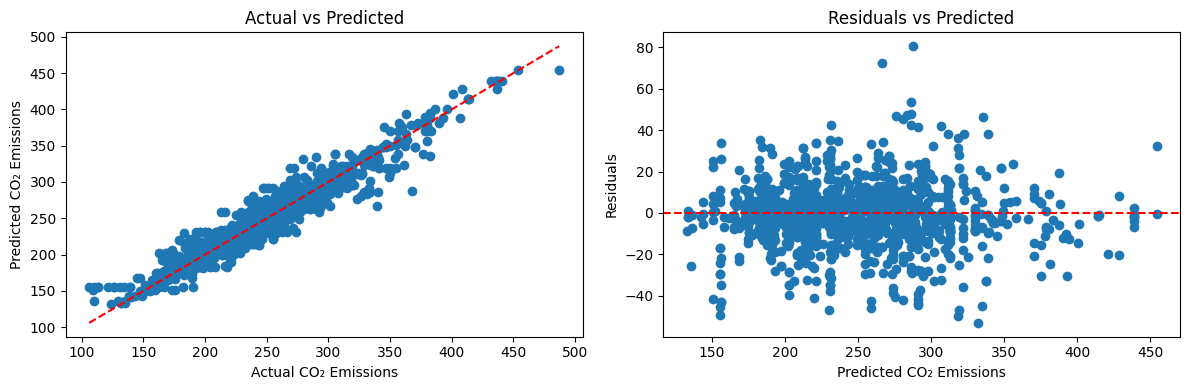

In [37]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Actual vs Predicted
axes[0].scatter(y_test, y_pred)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="red"
)
axes[0].set_xlabel("Actual CO₂ Emissions")
axes[0].set_ylabel("Predicted CO₂ Emissions")
axes[0].set_title("Actual vs Predicted")

#Residuals vs Predicted
axes[1].scatter(y_pred, residuals)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_xlabel("Predicted CO₂ Emissions")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs Predicted")

plt.tight_layout()
plt.show()

Linear Regression as Baseline Model

--- Linear Regression (Baseline) ---
MAE : 19.61026483224306
RMSE: 25.962244651084312
R²  : 0.8000210728995206


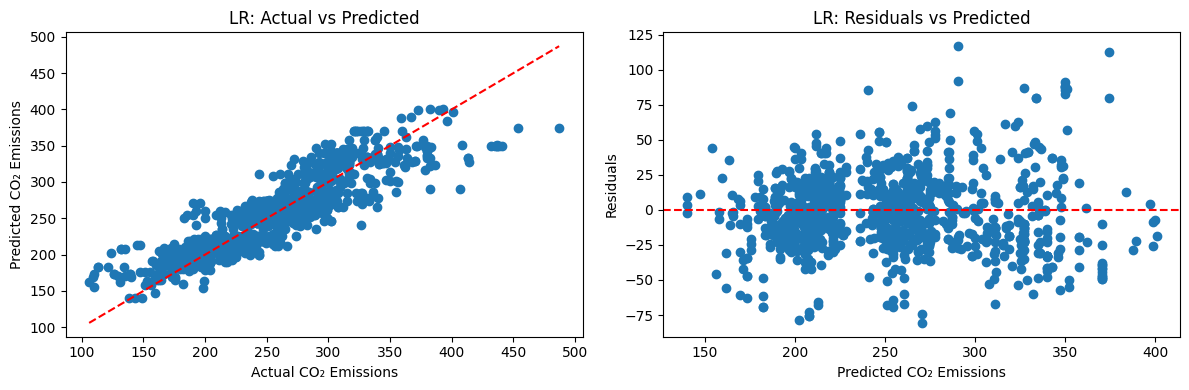

In [38]:
from sklearn.linear_model import LinearRegression

# Train Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

print("--- Linear Regression (Baseline) ---")
print("MAE :", mean_absolute_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("R²  :", r2_score(y_test, y_pred_lr))

# Append metrics to the results array
arr.append([
    mean_absolute_error(y_test, y_pred_lr),
    np.sqrt(mean_squared_error(y_test, y_pred_lr)),
    r2_score(y_test, y_pred_lr)
])

# Plotting
residuals_lr = y_test - y_pred_lr
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred_lr)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="red"
)
axes[0].set_xlabel("Actual CO₂ Emissions")
axes[0].set_ylabel("Predicted CO₂ Emissions")
axes[0].set_title("LR: Actual vs Predicted")

# Residuals vs Predicted
axes[1].scatter(y_pred_lr, residuals_lr)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_xlabel("Predicted CO₂ Emissions")
axes[1].set_ylabel("Residuals")
axes[1].set_title("LR: Residuals vs Predicted")

plt.tight_layout()
plt.show()


Result

In [39]:
arr = np.array(arr)

df_metrics = pd.DataFrame(
    arr.T,
    index=['MAE', 'RMSE', 'R²'],
    columns=['XGBoost', 'Decision Tree', 'Random Forest', 'Linear Regression']
)

df_metrics

,XGBoost,Decision Tree,Random Forest,Linear Regression
MAE,11.216862,11.106329,11.202404,19.610265
RMSE,15.404573,15.450722,15.399253,25.962245
R²,0.929596,0.929173,0.929644,0.800021
